## What Are the Most In-Demand Skills for the Top 3 Most Popular Data Roles?

### Methodology

1. Clean and preprocess the skills column.
2. Calculate skill counts based on `job_title_short`.
3. Calculate the percentage of job postings requiring each skill.
4. Visualize the final findings using charts.

In [52]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import seaborn as sns

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [11]:
df_India = df[df['job_country'] == 'India']
df_India

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
16,Data Engineer,Big Data Engineer,"Pune, Maharashtra, India",via LinkedIn,Full-time,False,India,2023-06-15 13:28:03,False,False,India,NaN,NaN,NaN,Hexaware Technologies,"[powershell, python, sql, mysql, sql server, d...","{'cloud': ['databricks', 'azure'], 'databases'..."
19,Data Scientist,Data Scientist,"Pune, Maharashtra, India",via Indeed,Full-time,False,India,2023-04-26 13:20:12,False,False,India,NaN,NaN,NaN,Bitwise Solutions,"[r, sql, python, scala, java, c++, hadoop, tab...","{'analyst_tools': ['tableau'], 'libraries': ['..."
29,Data Scientist,Data Scientist,"Pune, Maharashtra, India",via Exusia,Full-time,False,India,2023-03-26 13:16:20,False,False,India,NaN,NaN,NaN,Exusia,NaN,NaN
38,Data Analyst,Data Quality and Governance Analyst 1,India,via Trabajo.org,Full-time,False,India,2023-07-23 13:24:57,False,False,India,NaN,NaN,NaN,"Jones Lang LaSalle IP, Inc","[sql, python, databricks, power bi, excel, wor...","{'analyst_tools': ['power bi', 'excel', 'word'..."
42,Senior Data Engineer,"Senior Data Engineer(Python)-1563,1637&1633","Chennai, Tamil Nadu, India",via HR Software For Growing Businesses | Fresh...,Full-time,False,India,2023-11-10 13:30:41,True,False,India,NaN,NaN,NaN,CESIT,"[python, sql, aws, pyspark, docker, jira]","{'async': ['jira'], 'cloud': ['aws'], 'librari..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785712,Data Engineer,India - Collections Analyst II,India,melalui BeBee India,Pekerjaan tetap,False,India,2023-03-13 06:16:31,False,False,India,NaN,NaN,NaN,Varite India Private Limited,"[excel, flow]","{'analyst_tools': ['excel'], 'other': ['flow']}"
785715,Data Analyst,Amul Careers 2023 - Apply Online - Data Analys...,India,melalui Jobsleworld - Jobs In India - Job Vaca...,Pekerjaan tetap,False,India,2023-03-13 06:16:28,False,False,India,NaN,NaN,NaN,Amul,NaN,NaN
785716,Software Engineer,Application Support Analyst,India,melalui BeBee India,Pekerjaan tetap,False,India,2023-03-13 06:16:31,False,False,India,NaN,NaN,NaN,CompuGroup Medical,"[c#, sql]","{'programming': ['c#', 'sql']}"
785718,Business Analyst,Senior Performance QA Analyst,India,melalui BeBee India,Pekerjaan tetap,False,India,2023-03-13 06:16:28,False,False,India,NaN,NaN,NaN,Diebold Nixdorf,NaN,NaN


In [9]:
df_skills = df_India.explode('job_skills')                 

df_skills[['job_title', 'job_skills']]  

,job_title,job_skills
16,Big Data Engineer,"[powershell, python, sql, mysql, sql server, d..."
19,Data Scientist,"[r, sql, python, scala, java, c++, hadoop, tab..."
29,Data Scientist,NaN
38,Data Quality and Governance Analyst 1,"[sql, python, databricks, power bi, excel, wor..."
42,"Senior Data Engineer(Python)-1563,1637&1633","[python, sql, aws, pyspark, docker, jira]"
...,...,...
785712,India - Collections Analyst II,"[excel, flow]"
785715,Amul Careers 2023 - Apply Online - Data Analys...,NaN
785716,Application Support Analyst,"[c#, sql]"
785718,Senior Performance QA Analyst,NaN


In [31]:


df_skills_count = df_skills.explode('job_skills').groupby(['job_skills', 'job_title_short']).size()
df_skills_count = df_skills_count.reset_index(name = 'skill_count')
df_skills_count

,job_skills,job_title_short,skill_count
0,airflow,Business Analyst,19
1,airflow,Cloud Engineer,29
2,airflow,Data Analyst,89
3,airflow,Data Engineer,2990
4,airflow,Data Scientist,327
...,...,...,...
1684,zoom,Data Scientist,32
1685,zoom,Senior Data Analyst,1
1686,zoom,Senior Data Engineer,14
1687,zoom,Senior Data Scientist,4


In [33]:
job_titles = df_India['job_title_short'].unique().tolist()
job_titles = sorted(job_titles[:3])  # Limiting to first 3 job titles for visualization

job_titles

['Data Analyst', 'Data Engineer', 'Data Scientist']

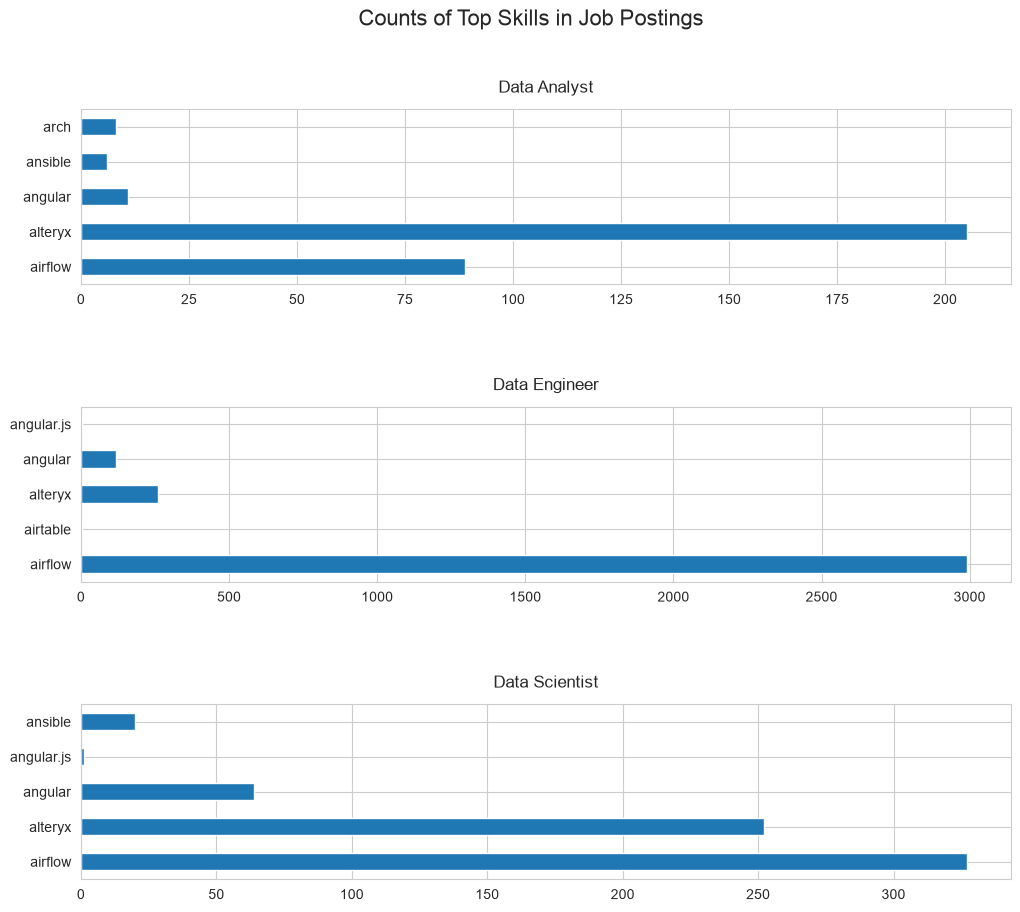

In [62]:
fig, ax = plt.subplots(len(job_titles), 1, figsize=(12, 10))

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_count[df_skills_count['job_title_short'] == job_title].head(5)[::-1]

    df_plot.plot(kind='barh', x='job_skills', y='skill_count', ax=ax[i])

    ax[i].invert_yaxis()
    ax[i].set_title(job_title, pad=12)
    ax[i].set_ylabel('')
    ax[i].legend().set_visible(False)

fig.suptitle('Counts of Top Skills in Job Postings', fontsize=16)

# Increase spacing between charts
fig.subplots_adjust(hspace=0.7)

plt.show()

In [42]:
df_job_title_count = df_India['job_title_short'].value_counts().reset_index(name='jobs_total')

In [48]:
df_skills_perc = pd.merge(df_skills_count,df_job_title_count,how= 'left',on='job_title_short')
df_skills_perc['skill_percent'] =  100 * df_skills_perc['skill_count']/df_skills_perc['jobs_total'] 
df_skills_perc

,job_skills,job_title_short,skill_count,jobs_total,skill_percent
0,airflow,Business Analyst,19,1887,1.006889
1,airflow,Cloud Engineer,29,351,8.262108
2,airflow,Data Analyst,89,6121,1.454011
3,airflow,Data Engineer,2990,19062,15.685657
4,airflow,Data Scientist,327,13279,2.462535
...,...,...,...,...,...
1684,zoom,Data Scientist,32,13279,0.240982
1685,zoom,Senior Data Analyst,1,1083,0.092336
1686,zoom,Senior Data Engineer,14,4353,0.321617
1687,zoom,Senior Data Scientist,4,2486,0.160901


In [40]:
df_skills_count

,job_skills,job_title_short,skill_count
0,airflow,Business Analyst,19
1,airflow,Cloud Engineer,29
2,airflow,Data Analyst,89
3,airflow,Data Engineer,2990
4,airflow,Data Scientist,327
...,...,...,...
1684,zoom,Data Scientist,32
1685,zoom,Senior Data Analyst,1
1686,zoom,Senior Data Engineer,14
1687,zoom,Senior Data Scientist,4


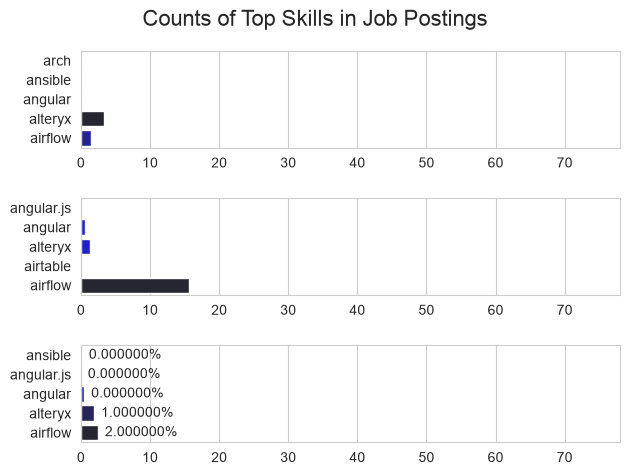

In [61]:
fig , ax = plt.subplots(len(job_titles),1)
sns.set_style("whitegrid")
for i ,job_title in enumerate(job_titles):
    df_plot = df_skills_perc[df_skills_perc['job_title_short'] == job_title].head(5)
    #df_plot.plot (kind='barh', x='job_skills', y='skill_percent', ax =ax[i], title=job_title)
    
    sns.barplot(data=df_plot, x='skill_percent', y='job_skills', ax=ax[i],hue='skill_count',palette='dark:b_r')
    ax[i].invert_yaxis()
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].get_legend().remove()
    ax[i].set_xlim(0,78)

for n,v in enumerate(df_plot['skill_percent']):
   ax[i].text(v+1,n,f'{int(v):0f}%',va='center')

if i != len(job_titles)-1:
   ax[i].set_xticks([])

fig.suptitle('Counts of Top Skills in Job Postings', fontsize=16) 
fig.tight_layout(h_pad=2.0) # fix the overlap 
plt.show()